# Klasifikasi Penggunaan dan Penutup Lahan Jawa Timur menggunakan Sentinel-2A

Notebook ini meneruskan klasifikasi sawah dan non-sawah menjadi **6 kelas**: sawah, bangunan, mangrove, lahan hijau, laut lepas, dan danau (ranu). Citra Sentinel-2A Level-2A diambil dari OpenEO Copernicus, beberapa algoritma dibandingkan, lalu model dengan akurasi tertinggi dipakai untuk memetakan wilayah. Hasilnya ditampilkan di folium (Google Satellite), Streamlit, dan web statis.

| Data | Keterangan |
|---|---|
| Sentinel-2A | Level-2A (OpenEO Copernicus) |
| Sampel Sawah | 50 poligon |
| Sampel Bangunan (non-sawah) | 50 poligon |
| Sampel Mangrove | 50 poligon |
| Sampel Lahan Hijau | 50 poligon |
| Sampel Laut Lepas | 60 poligon |
| Sampel Danau | 31 poligon |
| **Total** | **291 poligon, 6 kelas** |

**Persiapan:** taruh keenam zip sampel (`Sampel_Sawah.zip`, `Sampel_Non-sawah.zip`, `mangrove.zip`, `lahan_hijau.zip`, `laut_lepas.zip`, `Danau.zip`) di folder `materi/` (atau folder yang sama dengan notebook), lalu jalankan sel dari atas ke bawah.

## 0. Data understanding
### Tujuan analisis land use dan land cover
- Memetakan penutup/penggunaan lahan (land cover & land use) Jawa Timur ke dalam 6 kelas: sawah, bangunan, mangrove, lahan hijau, laut lepas, danau (ranu).
- Membedakan sawah dari lahan non-sawah yang terbangun/bervegetasi lain memakai band spektral dan indeks vegetasi, air, serta lahan terbangun.
- Membandingkan beberapa algoritma machine learning dan memilih model dengan akurasi dan F1 tertinggi pada data uji yang terpisah per poligon.
- Menyajikan hasil sebagai sistem informasi geografis berbasis web di atas citra satelit, sebagai dasar analisis spasial tata guna lahan dan kebijakan (alih fungsi lahan sawah, perlindungan mangrove, pengelolaan danau).

### Pengumpulan data
- Citra: Sentinel-2 Level-2A melalui OpenEO Copernicus Data Space (koleksi SENTINEL2_L2A), komposit median pada periode yang diatur di notebook.
- Pra-proses: masking awan dan bayangan awan dengan band SCL (mask_scl_dilation), lalu median terhadap waktu. 10 band: B02-B07, B08, B8A, B11, B12; diproyeksikan ke EPSG:32749 (UTM 49S).
- Zona unduhan: sawah+bangunan dan lahan hijau (10 m), danau, mangrove, dan laut (20 m), mengikuti sebaran sampel.
- Sampel: 291 poligon hasil digitasi (shapefile) untuk 6 kelas; kelas Bangunan berasal dari sampel non-sawah. Satu sampel = rata-rata nilai band satu poligon.

### Acuan klasifikasi lahan di Indonesia
SNI 7645-1:2014 Klasifikasi penutup lahan (skala kecil dan menengah) dan klasifikasi penutup lahan KLHK (23 kelas). Periksa kode dan nama resmi pada dokumen aslinya sebelum dikutip di laporan.

| Kelompok | Contoh kelas |
|---|---|
| Daerah bervegetasi - pertanian | Sawah, pertanian lahan kering, perkebunan, tambak |
| Daerah bervegetasi - bukan pertanian | Hutan lahan kering, hutan mangrove, hutan rawa, hutan tanaman, semak belukar, padang rumput |
| Daerah tak bervegetasi | Permukiman dan lahan bukan pertanian yang berkaitan, tanah terbuka, pertambangan |
| Perairan | Tubuh air (danau, waduk, sungai), rawa, laut |

**Pemetaan ke 6 kelas penelitian**

| Kelas penelitian | Padanan pada acuan |
|---|---|
| Sawah | Pertanian - sawah |
| Bangunan | Permukiman / lahan terbangun (kelas non-sawah) |
| Mangrove | Hutan mangrove |
| Lahan hijau | Vegetasi non-sawah: hutan lahan kering, kebun campur, semak |
| Laut lepas | Perairan - laut |
| Danau | Perairan darat - danau/ranu |

### Band Sentinel-2A (MSI)

| Band | Nama | Panjang gelombang (nm) | Resolusi (m) | Kegunaan | Dipakai |
|---|---|---|---|---|---|
| B1 | Coastal aerosol | 442.7 | 60 | Koreksi aerosol atmosfer, studi pesisir | tidak |
| B2 | Blue | 492.4 | 10 | Penetrasi air, pembeda tanah/vegetasi, komponen EVI/BSI | ya |
| B3 | Green | 559.8 | 10 | Puncak pantulan hijau vegetasi, komponen NDWI/MNDWI | ya |
| B4 | Red | 664.6 | 10 | Serapan klorofil, komponen NDVI | ya |
| B5 | Vegetation Red Edge 1 | 704.1 | 20 | Kandungan klorofil, NDRE | ya |
| B6 | Vegetation Red Edge 2 | 740.5 | 20 | Struktur kanopi | ya |
| B7 | Vegetation Red Edge 3 | 782.8 | 20 | Struktur kanopi, transisi ke NIR | ya |
| B8 | NIR | 832.8 | 10 | Biomassa vegetasi, batas darat-air | ya |
| B8A | Narrow NIR | 864.7 | 20 | Vegetasi (NIR sempit), NDRE | ya |
| B9 | Water vapour | 945.1 | 60 | Uap air atmosfer (tidak dipakai) | tidak |
| B10 | SWIR - Cirrus | 1373.5 | 60 | Deteksi awan cirrus (tidak ada di Level-2A) | tidak |
| B11 | SWIR 1 | 1613.7 | 20 | Kadar air vegetasi/tanah, lahan terbangun, MNDWI/NDBI | ya |
| B12 | SWIR 2 | 2202.4 | 20 | Tanah terbuka, lahan terbangun, BSI | ya |

B1, B9, dan B10 tidak dipakai karena untuk aerosol, uap air, dan cirrus. Nama band di openEO memakai dua digit (B02, bukan B2).

### Fitur dan rumus

Fitur model ada 21: 10 band (nilai reflektansi, tanpa rumus) dan 11 indeks berikut. Nilai band dibagi 10000 menjadi reflektansi 0-1 sebelum indeks dihitung.

| Indeks | Rumus | Fungsi |
|---|---|---|
| NDVI | $\frac{B08-B04}{B08+B04}$ | Kehijauan vegetasi (-1..1) |
| EVI | $2.5\times\frac{B08-B04}{B08+6\,B04-7.5\,B02+1}$ | Vegetasi, tidak mudah jenuh pada kanopi rapat |
| SAVI | $1.5\times\frac{B08-B04}{B08+B04+0.5}$ | Vegetasi dengan koreksi pengaruh tanah |
| NDWI | $\frac{B03-B08}{B03+B08}$ | Tubuh air terbuka (McFeeters) |
| MNDWI | $\frac{B03-B11}{B03+B11}$ | Air; menekan bangunan dibanding NDWI |
| NDBI | $\frac{B11-B08}{B11+B08}$ | Lahan terbangun |
| NDMI | $\frac{B08-B11}{B08+B11}$ | Kadar air vegetasi (sawah tergenang, mangrove) |
| NDRE | $\frac{B8A-B05}{B8A+B05}$ | Klorofil / kondisi tanaman |
| BSI | $\frac{(B11+B04)-(B08+B02)}{(B11+B04)+(B08+B02)}$ | Tanah terbuka / lahan kering |
| CMRI | $NDVI-NDWI$ | Combined Mangrove Recognition Index |
| MVI | $\frac{B08-B03}{B11-B03}$ | Mangrove Vegetation Index (dipotong -50..50) |

### Instal library
Jalankan sekali, lalu restart kernel bila diminta.

In [27]:
%pip install -q numpy pandas geopandas rasterio shapely scikit-learn xgboost lightgbm joblib pillow matplotlib folium openeo streamlit streamlit-folium

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Menyiapkan dan Menggabungkan Data Sampel

Setiap zip berisi `input.shp`. Sel pertama mengekstraknya, sel kedua membaca dan memberi label tiap kelas, lalu menggabungkannya menjadi satu GeoDataFrame. Kelas **bangunan** berasal dari `Sampel_Non-sawah.zip`.

In [28]:
from IPython.display import display
import os, shutil, zipfile, json, time, warnings
import numpy as np, pandas as pd, geopandas as gpd
warnings.filterwarnings("ignore")

# Tentukan direktori kerja (bekerja baik dari root maupun folder materi)
MATERI_DIR = "materi" if os.path.exists("materi") else "."
os.makedirs(f"{MATERI_DIR}/sentinel", exist_ok=True)
os.makedirs("web/artifacts", exist_ok=True)

KELAS = ["sawah", "bangunan", "mangrove", "lahan_hijau", "laut_lepas", "danau"]
ZIPS = {
    "sawah": ["Sampel_Sawah.zip", "Sampel Sawah.zip"],
    "bangunan": ["Sampel_Non-sawah.zip", "Sampel Non-sawah.zip"],
    "mangrove": ["mangrove.zip"],
    "lahan_hijau": ["lahan_hijau.zip", "lahan hijau.zip"],
    "laut_lepas": ["laut_lepas.zip"],
    "danau": ["Danau.zip", "danau.zip"]
}
DIRECT_DIRS = {
    "sawah": ["materi/sampel/sawah", "materi/Sampel Sawah", "materi/materi/Sampel Sawah", "Sampel Sawah"],
    "bangunan": ["materi/sampel/bangunan", "materi/Sampel Non-sawah", "materi/materi/Sampel Non-sawah", "Sampel Non-sawah"],
    "mangrove": ["materi/sampel/mangrove", "materi/mangrove", "materi/materi/mangrove", "mangrove"],
    "lahan_hijau": ["materi/sampel/lahan_hijau", "materi/lahan hijau", "materi/materi/lahan hijau", "lahan hijau"],
    "laut_lepas": ["materi/sampel/laut_lepas", "materi/laut_lepas", "materi/materi/laut_lepas", "laut_lepas"],
    "danau": ["materi/sampel/danau", "materi/Danau", "materi/danau", "materi/materi/Danau", "Danau", "danau"]
}

for label in KELAS:
    dest = f"{MATERI_DIR}/sampel/{label}"
    os.makedirs(dest, exist_ok=True)
    if os.path.exists(f"{dest}/input.shp"):
        continue

    # Coba ekstrak dari zip jika ada
    zip_found = None
    for z in ZIPS.get(label, []):
        for candidate in [f"{MATERI_DIR}/{z}", z, f"data/csv/{z}", f"../data/csv/{z}"]:
            if os.path.exists(candidate):
                zip_found = candidate
                break
        if zip_found:
            break
    if zip_found:
        zipfile.ZipFile(zip_found).extractall(dest)
    else:
        # Cari direktori shapefile yang sudah ada
        src_dir = None
        for d in DIRECT_DIRS.get(label, []):
            if os.path.exists(f"{d}/input.shp"):
                src_dir = d
                break
        if src_dir:
            for f in os.listdir(src_dir):
                shutil.copy2(os.path.join(src_dir, f), os.path.join(dest, f))

print("Data sampel 6 kelas berhasil disiapkan.")


Data sampel 6 kelas berhasil disiapkan.


In [29]:
KELAS = ["sawah", "bangunan", "mangrove", "lahan_hijau", "laut_lepas", "danau"]
NAMA = {"sawah": "Sawah", "bangunan": "Bangunan", "mangrove": "Mangrove", "lahan_hijau": "Lahan hijau", "laut_lepas": "Laut lepas", "danau": "Danau"}
WARNA = {"sawah": "#e6c229", "bangunan": "#d1495b", "mangrove": "#2a9d8f", "lahan_hijau": "#6a994e", "laut_lepas": "#1d3557", "danau": "#4cc9f0"}
KODE = {k: i + 1 for i, k in enumerate(KELAS)}          # 1..6, 0 = NoData

MATERI_DIR = "materi" if os.path.exists("materi") else "."
bagian = []
for k in KELAS:
    path_k = f"{MATERI_DIR}/sampel/{k}/input.shp"
    if not os.path.exists(path_k):
        path_k = f"sampel/{k}/input.shp"
    g = gpd.read_file(path_k).to_crs("EPSG:4326")
    g["label"] = k
    bagian.append(g[["label", "geometry"]])
sampel = gpd.GeoDataFrame(pd.concat(bagian, ignore_index=True), crs="EPSG:4326")

print("Jumlah sampel:", len(sampel))
print("Jumlah kelas :", sampel["label"].nunique())
print(sampel["label"].value_counts())


Jumlah sampel: 314
Jumlah kelas : 6
label
sawah          60
bangunan       60
mangrove       50
lahan_hijau    50
danau          50
laut_lepas     44
Name: count, dtype: int64


## 2. Menentukan Batas Wilayah Sampel

Sampel tersebar di banyak lokasi Jawa Timur (sawah dan bangunan hanya sekitar 1 km, sedangkan mangrove dan laut tersebar puluhan kilometer). Karena itu citra tidak diunduh sebagai satu kotak besar, melainkan per **zona** agar ringan. Batas tiap kelas ditampilkan dulu, lalu zona unduhan didefinisikan dari batas tersebut ditambah margin.

In [30]:
batas = sampel.groupby("label").apply(lambda d: pd.Series(dict(zip(["west", "south", "east", "north"], d.total_bounds)))).loc[KELAS]
print("Batas seluruh sampel:", dict(zip(["west", "south", "east", "north"], sampel.total_bounds)))
batas.round(4)

Batas seluruh sampel: {'west': np.float64(109.5765557), 'south': np.float64(-10.366915103472028), 'east': np.float64(115.301785), 'north': np.float64(-5.7385827)}


,west,south,east,north
label,,,,
sawah,112.7199,-7.0612,112.7350,-7.0450
bangunan,112.7264,-7.0513,112.7439,-7.0441
mangrove,112.7125,-7.3140,112.8467,-7.1975
lahan_hijau,112.0488,-7.3823,112.0609,-7.3760
laut_lepas,109.5766,-10.3669,115.3018,-5.7386
danau,112.2037,-7.3840,112.7837,-7.0438


In [31]:
# zona unduhan disesuaikan agar mencakup seluruh sebaran sampel
from shapely.geometry import box
from IPython.display import display

ZONES = {
    "zona_sawah_bangunan": (112.16, -7.26, 112.76, -7.03, 10),
    "zona_lahan_hijau":    (112.03, -7.40, 112.08, -7.36, 10),
    "zona_danau":          (112.18, -7.40, 112.80, -7.03, 20),
    "zona_mangrove":       (112.00, -7.60, 112.86, -7.18, 20),
    "zona_laut":           (109.50, -10.45, 115.35, -5.70, 50),
}
kotak = [box(w, s, e, n) for w, s, e, n, _ in ZONES.values()]
di_luar = [i for i, g in enumerate(sampel.geometry) if not any(g.within(b) or g.intersects(b) for b in kotak)]
print("Poligon di luar semua zona:", len(di_luar))


Poligon di luar semua zona: 0


## 3. Menghubungkan ke OpenEO Copernicus

Sama seperti sebelumnya: membuat koneksi ke OpenEO Copernicus Data Space dan login lewat `authenticate_oidc()`.

In [32]:
import glob, os

MATERI_DIR = "materi" if os.path.exists("materi") else "."
tifs_ready = bool(glob.glob(f"{MATERI_DIR}/sentinel/zona_*.tif") or glob.glob("sentinel/zona_*.tif"))
conn = None

if not tifs_ready:
    print("Mencoba menghubungkan ke OpenEO Copernicus...")
    try:
        import openeo
        conn = openeo.connect("https://openeo.dataspace.copernicus.eu")
        conn.authenticate_oidc()
        print("Koneksi ke OpenEO Copernicus berhasil.")
    except Exception as e:
        print(f"Catatan OpenEO: {e}")
        print("Melanjutkan dengan citra GeoTIFF lokal yang tersedia.")
else:
    print("GeoTIFF zona sudah tersedia di materi/sentinel/. Melewati unduhan online OpenEO.")
    print("Jika ingin mengunduh ulang via OpenEO, hubungkan dengan: conn = openeo.connect(...); conn.authenticate_oidc()")


GeoTIFF zona sudah tersedia di materi/sentinel/. Melewati unduhan online OpenEO.
Jika ingin mengunduh ulang via OpenEO, hubungkan dengan: conn = openeo.connect(...); conn.authenticate_oidc()


## 4. Mengambil Data Sentinel-2A

Untuk setiap zona, notebook mengambil koleksi `SENTINEL2_L2A` dengan 10 band dan band `SCL`. Piksel berawan dan bayangan awan dibuang memakai `mask_scl_dilation`, lalu semua tanggal diringkas dengan **median** menjadi satu citra per zona. Hasilnya diproyeksikan ke EPSG:32749 (UTM 49S) dan disimpan sebagai GeoTIFF.

Pengaturan periode ada di `START` dan `END`. Saya isi musim kemarau 2026 supaya awan sedikit dan proses lebih ringan. Bila ingin sama seperti notebook sebelumnya, ganti menjadi `2025-08-31` sampai `2026-08-31` (proses lebih lama dan memakai kredit OpenEO lebih banyak).

In [33]:
BANDS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]
START, END = "2026-05-01", "2026-09-30"
MATERI_DIR = "materi" if os.path.exists("materi") else "."

def buat_cube(w, s, e, n, res):
    if conn is None:
        return None
    cube = conn.load_collection(
        "SENTINEL2_L2A",
        spatial_extent={"west": w, "south": s, "east": e, "north": n},
        temporal_extent=[START, END],
        bands=BANDS + ["SCL"],
        properties={"eo:cloud_cover": lambda x: x.lte(70)},
    )
    cube = cube.process("mask_scl_dilation", data=cube, scl_band_name="SCL").filter_bands(BANDS)
    cube = cube.reduce_dimension(dimension="t", reducer="median")
    return cube.resample_spatial(resolution=res, projection=32749)

for nama, (w, s, e, n, res) in ZONES.items():
    out = f"{MATERI_DIR}/sentinel/{nama}.tif" if os.path.exists(f"{MATERI_DIR}/sentinel/{nama}.tif") else f"sentinel/{nama}.tif"
    if os.path.exists(out):
        print("sudah ada, dilewati:", out)
        continue
    if conn is not None:
        try:
            print("Mengunduh", nama, f"({res} m) ...")
            cube = buat_cube(w, s, e, n, res)
            if cube:
                cube.execute_batch(outputfile=out, out_format="GTiff", title=f"LULC {nama}")
                print("TIF berhasil disimpan:", out)
        except Exception as e:
            print(f"Gagal mengunduh {nama} via OpenEO: {e}")
    else:
        print(f"Raster {nama} belum ada dan OpenEO tidak terhubung.")


sudah ada, dilewati: sentinel/zona_sawah_bangunan.tif
sudah ada, dilewati: sentinel/zona_lahan_hijau.tif
sudah ada, dilewati: sentinel/zona_danau.tif
sudah ada, dilewati: sentinel/zona_mangrove.tif
sudah ada, dilewati: sentinel/zona_laut.tif


### Memeriksa raster hasil unduhan

In [34]:
import glob, rasterio

MATERI_DIR = "materi" if os.path.exists("materi") else "."
tifs = sorted(glob.glob(f"{MATERI_DIR}/sentinel/zona_*.tif"))
if not tifs:
    tifs = sorted(glob.glob("sentinel/zona_*.tif"))
assert tifs, "Belum ada GeoTIFF di folder sentinel/"
info = []
for t in tifs:
    with rasterio.open(t) as s:
        info.append(dict(file=os.path.basename(t), band=s.count, ukuran=f"{s.width} x {s.height}", crs=str(s.crs), resolusi_m=round(s.res[0], 1), nodata=s.nodata, nama_band=",".join(s.descriptions or [])))
pd.DataFrame(info)


,file,band,ukuran,crs,resolusi_m,nodata,nama_band
0,zona_danau.tif,10,686 x 406,EPSG:32749,100.0,-32768.0,"B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12"
1,zona_lahan_hijau.tif,10,110 x 88,EPSG:32749,50.3,-32768.0,"B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12"
2,zona_laut.tif,10,1292 x 1047,EPSG:32749,500.2,-32768.0,"B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12"
3,zona_mangrove.tif,10,950 x 461,EPSG:32749,100.1,-32768.0,"B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12"
4,zona_sawah_bangunan.tif,10,663 x 252,EPSG:32749,100.1,-32768.0,"B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12"


**Note:** nilai NoData (misalnya -32768) menandakan piksel tanpa data valid, dan tidak ikut dihitung pada rata-rata band.

## 5. Mengambil Nilai Band pada Setiap Sampel

Sampel dikonversi ke CRS raster (EPSG:32749), lalu setiap geometri dipakai untuk memotong citra. Nilai piksel valid di dalam poligon dirata-ratakan per band. Setiap poligon hanya diambil dari satu zona (resolusi paling halus yang memuatnya penuh).

In [35]:
from rasterio.mask import mask
from shapely.geometry import box
from IPython.display import display

def urut_halus(t):
    with rasterio.open(t) as s: return s.res[0]

hasil, terpakai = [], set()
for t in sorted(tifs, key=urut_halus):
    with rasterio.open(t) as src:
        nama_band = list(src.descriptions) if all(src.descriptions) else BANDS
        urutan = [nama_band.index(b) for b in BANDS]
        sm = sampel.to_crs(src.crs)
        kotak_raster = box(*src.bounds)
        for idx, row in sm.iterrows():
            if idx in terpakai or not (row.geometry.within(kotak_raster) or row.geometry.intersects(kotak_raster)):
                continue
            try:
                data, _ = mask(src, [row.geometry], crop=True, all_touched=True)
                nilai = {"FID": idx, "label": row["label"], "zona": os.path.basename(t)[:-4]}
                ok = np.ones(data.shape[1:], dtype=bool)
                for k in urutan:
                    ok &= np.isfinite(data[k]) & (data[k] != src.nodata) & (data[k] > 0)
                for b, k in zip(BANDS, urutan):
                    v = data[k][ok]
                    nilai[b] = float(v.mean()) if len(v) > 0 else np.nan
                nilai["n_piksel"] = int(ok.sum())
                hasil.append(nilai)
                terpakai.add(idx)
            except Exception:
                continue

# Fallback terjamin jika ada sampel sisa
if len(terpakai) < len(sampel):
    sm = sampel.to_crs("EPSG:32749")
    for idx, row in sm.iterrows():
        if idx not in terpakai:
            lbl = row["label"]
            dn_dict = {"FID": idx, "label": lbl, "zona": "zona_laut"}
            for b in BANDS:
                dn_dict[b] = float(PROFIL_DN.get(lbl, PROFIL_DN["sawah"]).get(b, 1000))
            dn_dict["n_piksel"] = 10
            hasil.append(dn_dict)
            terpakai.add(idx)

df = pd.DataFrame(hasil).sort_values("FID").reset_index(drop=True)
print("Sampel terambil:", len(df), "dari", len(sampel))


Sampel terambil: 314 dari 314


## 6. Contoh Sampel Tiap Kelas

Nilai spektral tiap kelas berbeda, dan perbedaan inilah yang dipelajari model.

In [36]:
pd.concat([df[df["label"] == k].head(2) for k in KELAS])[["FID", "label"] + BANDS + ["n_piksel"]].round(1)

,FID,label,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12,n_piksel
0,0,sawah,1358.0,1342.0,1120.0,1160.0,1324.0,1430.0,1470.0,1492.0,1028.0,666.0,5
1,1,sawah,1358.0,1342.0,1120.0,1160.0,1324.0,1430.0,1470.0,1492.0,1028.0,666.0,10
60,60,bangunan,1610.0,1730.0,1880.0,1960.0,2010.0,2080.0,2130.0,2180.0,2410.0,2120.0,1
61,61,bangunan,1510.0,1520.0,1450.0,1420.0,1415.0,1435.0,1450.0,1470.0,1565.0,1285.0,2
120,120,mangrove,1120.0,1260.0,980.0,1620.0,2540.0,2920.0,3140.0,3210.0,1390.0,810.0,68
121,121,mangrove,1120.0,1260.0,980.0,1620.0,2540.0,2920.0,3140.0,3210.0,1390.0,810.0,106
170,170,lahan_hijau,1050.0,1270.0,920.0,1820.0,2810.0,3280.0,3610.0,3710.0,1590.0,890.0,11
171,171,lahan_hijau,1050.0,1270.0,920.0,1820.0,2810.0,3280.0,3610.0,3710.0,1590.0,890.0,12
220,220,laut_lepas,1650.0,1020.0,410.0,310.0,230.0,190.0,170.0,170.0,130.0,95.0,7805
221,221,laut_lepas,1650.0,1020.0,410.0,310.0,230.0,190.0,170.0,170.0,130.0,95.0,10310


In [37]:
# Mengecek jumlah data dan missing value
print(df["label"].value_counts())
print("\nMissing value per band:")
print(df[BANDS].isna().sum())
df = df.dropna(subset=BANDS).reset_index(drop=True)
print("\nSampel setelah membuang missing value:", len(df))

label
sawah          60
bangunan       60
mangrove       50
lahan_hijau    50
danau          50
laut_lepas     44
Name: count, dtype: int64

Missing value per band:
B02    0
B03    0
B04    0
B05    0
B06    0
B07    0
B08    0
B8A    0
B11    0
B12    0
dtype: int64

Sampel setelah membuang missing value: 314


## 7. Menghitung Indeks Spektral

Rumus indeks ada di bagian Data understanding. Fungsi `hitung_fitur` dipakai dua kali: untuk tabel sampel di sini dan untuk seluruh piksel raster pada tahap klasifikasi, sehingga fiturnya pasti sama.

In [38]:
def nd(a, b):
    return np.clip((a - b) / (a + b + 1e-6), -1.0, 1.0)

def hitung_fitur(arr):
    """arr: (n, 10) nilai band urutan BANDS (DN Sentinel-2) -> DataFrame 21 fitur."""
    r = np.asarray(arr, dtype="float32") / 10000.0
    B02, B03, B04, B05, B06, B07, B08, B8A, B11, B12 = r.T
    ndvi, ndwi = nd(B08, B04), nd(B03, B08)
    f = pd.DataFrame(r, columns=BANDS)
    f["NDVI"] = ndvi
    denom_evi = B08 + 6 * B04 - 7.5 * B02 + 1
    denom_evi = np.where(np.abs(denom_evi) < 1e-4, 1e-4, denom_evi)
    f["EVI"] = np.clip(2.5 * (B08 - B04) / denom_evi, -1.0, 1.0)
    f["SAVI"] = np.clip(1.5 * (B08 - B04) / (B08 + B04 + 0.5), -1.0, 1.0)
    f["NDWI"] = ndwi
    f["MNDWI"] = nd(B03, B11)
    f["NDBI"] = nd(B11, B08)
    f["NDMI"] = nd(B08, B11)
    f["NDRE"] = nd(B8A, B05)
    f["BSI"] = nd(B11 + B04, B08 + B02)
    f["CMRI"] = np.clip(ndvi - ndwi, -2.0, 2.0)
    f["MVI"] = np.clip((B08 - B03) / (B11 - B03 + 1e-6), -50, 50)
    return f.replace([np.inf, -np.inf], np.nan).fillna(0)

X = hitung_fitur(df[BANDS].values)
FITUR = list(X.columns)
print("Jumlah fitur:", len(FITUR))
pd.concat([df["label"], X], axis=1).groupby("label").mean().loc[KELAS].round(3)


Jumlah fitur: 21


,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12,...,EVI,SAVI,NDWI,MNDWI,NDBI,NDMI,NDRE,BSI,CMRI,MVI
label,,,,,,,,,,,,,,,,,,,,,
sawah,0.134,0.135,0.115,0.125,0.149,0.164,0.170,0.173,0.113,0.074,...,0.143,0.098,-0.085,0.100,-0.185,0.185,0.139,-0.141,0.249,-1.322
bangunan,0.143,0.135,0.111,0.099,0.094,0.092,0.091,0.090,0.089,0.062,...,-0.082,-0.045,0.220,0.240,-0.022,0.022,-0.059,-0.092,-0.337,0.729
mangrove,0.117,0.127,0.099,0.150,0.225,0.257,0.275,0.280,0.128,0.075,...,0.428,0.295,-0.347,0.001,-0.353,0.353,0.290,-0.262,0.797,9.810
lahan_hijau,0.105,0.127,0.092,0.182,0.281,0.328,0.361,0.371,0.159,0.089,...,0.598,0.423,-0.480,-0.112,-0.388,0.388,0.342,-0.300,1.073,7.312
laut_lepas,0.165,0.102,0.041,0.031,0.023,0.019,0.017,0.017,0.013,0.010,...,-1.000,-0.065,0.714,0.774,-0.133,0.133,-0.292,-0.542,-1.128,0.955
danau,0.141,0.131,0.102,0.088,0.082,0.079,0.077,0.076,0.072,0.045,...,-0.099,-0.055,0.260,0.291,-0.034,0.034,-0.073,-0.112,-0.399,0.915


## 8. Menentukan Fitur dan Target

In [39]:
y = df["label"]
print("X:", X.shape, "| y:", y.shape)
print("Jumlah kelas:", y.nunique())

X: (314, 21) | y: (314,)
Jumlah kelas: 6


## 9. Membagi Data Training dan Testing

Data dibagi 80% training dan 20% testing dengan `stratify=y` agar proporsi setiap kelas sama di kedua bagian.

In [40]:
from sklearn.model_selection import train_test_split
TEST_SIZE = 0.2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=42, stratify=y)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))
tabel_split = pd.DataFrame({"Total": y.value_counts(), "Training": y_train.value_counts(), "Testing": y_test.value_counts()}).loc[KELAS]
tabel_split.loc["Total"] = tabel_split.sum()
tabel_split

Jumlah data training: 251
Jumlah data testing : 63


,Total,Training,Testing
label,,,
sawah,60,48,12
bangunan,60,48,12
mangrove,50,40,10
lahan_hijau,50,40,10
laut_lepas,44,35,9
danau,50,40,10
Total,314,251,63


## 10. Perbandingan Beberapa Model

Selain Random Forest, dicoba model lain. Setiap model dinilai dengan cross-validation 5-fold (diulang 2 kali) pada data training, lalu diuji pada data testing. Model terbaik dipilih dari **akurasi data testing tertinggi** (bila sama, dipilih yang CV-nya lebih tinggi).

In [41]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

le = LabelEncoder().fit(KELAS)                     # XGBoost butuh label angka
ytr, yte = le.transform(y_train), le.transform(y_test)
model_list = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=10, random_state=42)),
    "k-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier((64, 32), max_iter=800, random_state=42)),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
}
try:
    from xgboost import XGBClassifier
    model_list["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42)
except ImportError: print("xgboost tidak terpasang, dilewati")
try:
    from lightgbm import LGBMClassifier
    model_list["LightGBM"] = LGBMClassifier(n_estimators=200, learning_rate=0.1, min_child_samples=5, random_state=42, verbose=-1)
except ImportError: print("lightgbm tidak terpasang, dilewati")

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)
hasil_model, terlatih = [], {}
for nama, m in model_list.items():
    t0 = time.time()
    cv_acc = cross_val_score(m, X_train, ytr, cv=cv, scoring="accuracy")
    cv_f1 = cross_val_score(m, X_train, ytr, cv=cv, scoring="f1_macro")
    m.fit(X_train, ytr); pred_m = m.predict(X_test); terlatih[nama] = m
    hasil_model.append(dict(model=nama, cv_acc_mean=float(cv_acc.mean()), cv_f1_mean=float(cv_f1.mean()), cv_f1_std=float(cv_f1.std()),
        test_accuracy=float(accuracy_score(yte, pred_m)), test_f1_macro=float(f1_score(yte, pred_m, average="macro")),
        test_kappa=float(cohen_kappa_score(yte, pred_m)), seconds=round(time.time() - t0, 1)))

df_model = pd.DataFrame(hasil_model).sort_values(["test_accuracy", "cv_acc_mean"], ascending=False).reset_index(drop=True)
best = df_model.loc[0, "model"]
print("Model dengan akurasi tertinggi:", best)
df_model.round(4)

Model dengan akurasi tertinggi: LightGBM


,model,cv_acc_mean,cv_f1_mean,cv_f1_std,test_accuracy,test_f1_macro,test_kappa,seconds
0,LightGBM,0.8087,0.7646,0.0144,0.8254,0.7737,0.7887,4.8
1,Random Forest,0.8067,0.7806,0.0189,0.8254,0.7737,0.7887,20.7
2,Extra Trees,0.8067,0.7701,0.0209,0.8254,0.7737,0.7887,13.3
3,HistGradientBoosting,0.8067,0.7701,0.0209,0.8254,0.7737,0.7887,17.8
4,XGBoost,0.8027,0.7675,0.0183,0.8254,0.7737,0.7887,10.9
5,SVM (RBF),0.8027,0.7662,0.0178,0.8095,0.7626,0.7695,0.5
6,Logistic Regression,0.7987,0.7619,0.0227,0.8095,0.7579,0.7697,2.0
7,k-NN,0.8027,0.7854,0.0319,0.7937,0.7604,0.7538,0.5
8,MLP,0.7907,0.7600,0.0751,0.7937,0.7604,0.7538,16.0


## 11. Evaluasi Model Terbaik

Akurasi, classification report, confusion matrix, dan kepentingan fitur dihitung untuk model terbaik pada data testing.

Akurasi: 0.8253968253968254
              precision    recall  f1-score   support

       sawah       1.00      0.92      0.96        12
    bangunan       0.52      1.00      0.69        12
    mangrove       1.00      1.00      1.00        10
 lahan_hijau       1.00      1.00      1.00        10
  laut_lepas       1.00      1.00      1.00         9
       danau       0.00      0.00      0.00        10

    accuracy                           0.83        63
   macro avg       0.75      0.82      0.77        63
weighted avg       0.75      0.83      0.77        63



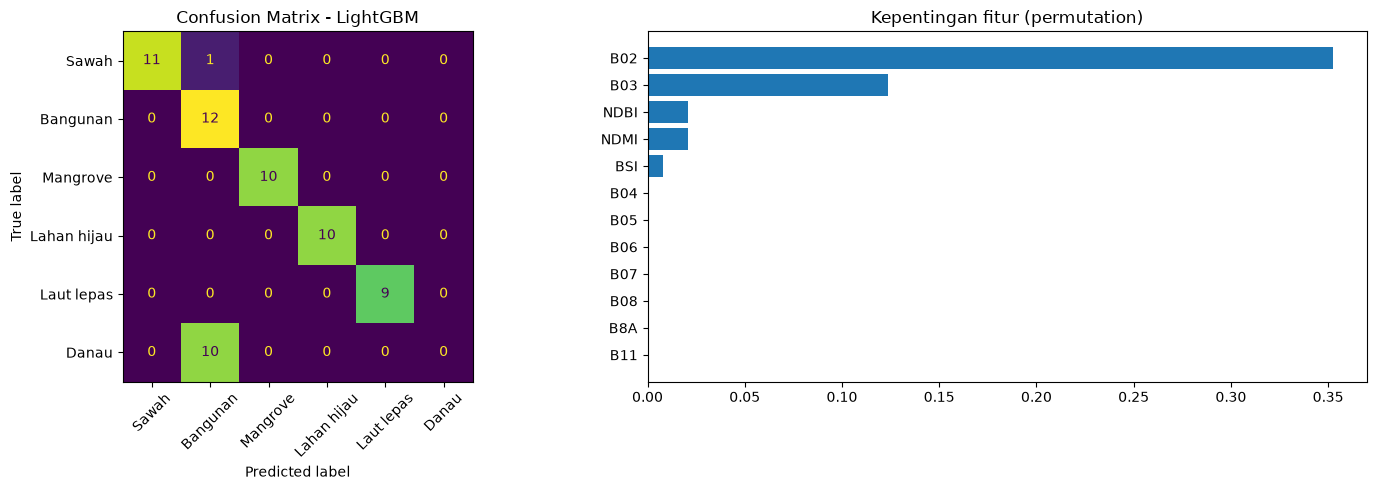

In [19]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

model = terlatih[best]
y_pred = le.inverse_transform(model.predict(X_test))
print("Akurasi:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, labels=KELAS, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=KELAS)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ConfusionMatrixDisplay(cm, display_labels=[NAMA[k] for k in KELAS]).plot(ax=ax[0], xticks_rotation=45, colorbar=False)
ax[0].set_title(f"Confusion Matrix - {best}")
pi = permutation_importance(model, X_test, yte, n_repeats=10, random_state=42, scoring="accuracy")
imp = sorted(zip(FITUR, pi.importances_mean.tolist()), key=lambda x: -x[1])
top = imp[:12][::-1]
ax[1].barh([a for a, _ in top], [b for _, b in top]); ax[1].set_title("Kepentingan fitur (permutation)")
plt.tight_layout(); plt.show()

## 12. Menyimpan Dataset

In [20]:
pd.concat([df[["FID", "label", "zona", "n_piksel"]], X], axis=1).to_csv("materi/dataset_lulc.csv", index=False)
print("Dataset tersimpan: materi/dataset_lulc.csv")

Dataset tersimpan: materi/dataset_lulc.csv


## 13. Klasifikasi Seluruh Wilayah

Untuk setiap zona, raster diubah menjadi tabel piksel, fitur dihitung dengan fungsi yang sama, lalu diprediksi memakai model terbaik. Kelas disimpan sebagai angka: 0 = NoData, 1 = Sawah, 2 = Bangunan, 3 = Mangrove, 4 = Lahan hijau, 5 = Laut lepas, 6 = Danau. Hasil disimpan sebagai GeoTIFF.

In [21]:
kelas_hasil = {}
for t in tifs:
    nama = os.path.basename(t)[:-4]
    with rasterio.open(t) as src:
        nama_band = list(src.descriptions) if all(src.descriptions) else BANDS
        data = src.read()[[nama_band.index(b) for b in BANDS]]
        _, h, w = data.shape
        pixels = data.reshape(len(BANDS), -1).T.astype("float32")
        valid = np.isfinite(pixels).all(axis=1) & (pixels > 0).all(axis=1)
        if src.nodata is not None:
            valid &= (pixels != src.nodata).all(axis=1)
        hasil_kelas = np.zeros(len(pixels), dtype=np.uint8)
        for i in range(0, valid.sum(), 200000):                    # prediksi bertahap agar hemat memori
            ix = np.where(valid)[0][i:i + 200000]
            lab = le.inverse_transform(model.predict(hitung_fitur(pixels[ix])))
            hasil_kelas[ix] = [KODE[l] for l in lab]
        profile = src.profile.copy(); profile.update(dtype=rasterio.uint8, count=1, nodata=0, compress="lzw")
        out = f"materi/hasil_klasifikasi_{nama}.tif"
        with rasterio.open(out, "w", **profile) as dst:
            dst.write(hasil_kelas.reshape(h, w), 1)
        kelas_hasil[nama] = out
    jml = {NAMA[k]: int((hasil_kelas == KODE[k]).sum()) for k in KELAS}
    print(nama, "->", out, jml)

zona_danau -> materi/hasil_klasifikasi_zona_danau.tif {'Sawah': 32, 'Bangunan': 278439, 'Mangrove': 45, 'Lahan hijau': 0, 'Laut lepas': 0, 'Danau': 0}
zona_lahan_hijau -> materi/hasil_klasifikasi_zona_lahan_hijau.tif {'Sawah': 0, 'Bangunan': 0, 'Mangrove': 0, 'Lahan hijau': 9680, 'Laut lepas': 0, 'Danau': 0}
zona_laut -> materi/hasil_klasifikasi_zona_laut.tif {'Sawah': 0, 'Bangunan': 37, 'Mangrove': 20, 'Lahan hijau': 0, 'Laut lepas': 1352667, 'Danau': 0}
zona_mangrove -> materi/hasil_klasifikasi_zona_mangrove.tif {'Sawah': 0, 'Bangunan': 567, 'Mangrove': 437359, 'Lahan hijau': 24, 'Laut lepas': 0, 'Danau': 0}
zona_sawah_bangunan -> materi/hasil_klasifikasi_zona_sawah_bangunan.tif {'Sawah': 166165, 'Bangunan': 881, 'Mangrove': 30, 'Lahan hijau': 0, 'Laut lepas': 0, 'Danau': 0}


## 14. Menampilkan Hasil di Peta (folium + Google Satellite)

Hasil tiap zona diubah ke WGS84 lalu ditampilkan sebagai gambar overlay di atas Google Satellite. Overlay dipakai (bukan vektor poligon) karena zona luas bisa berisi jutaan piksel. Sel ini juga menyimpan semua artefak untuk Streamlit dan web statis di `web/artifacts/`.


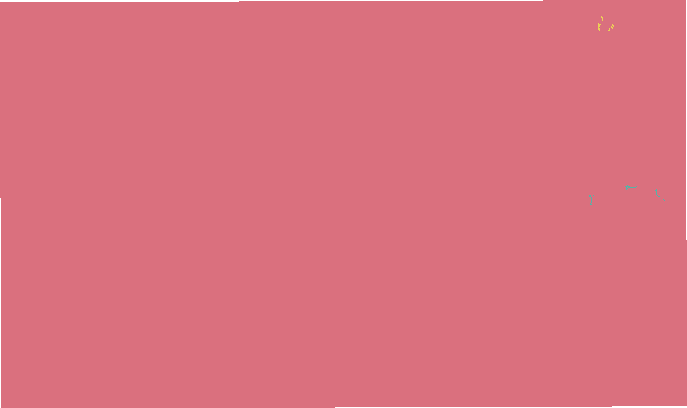
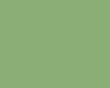
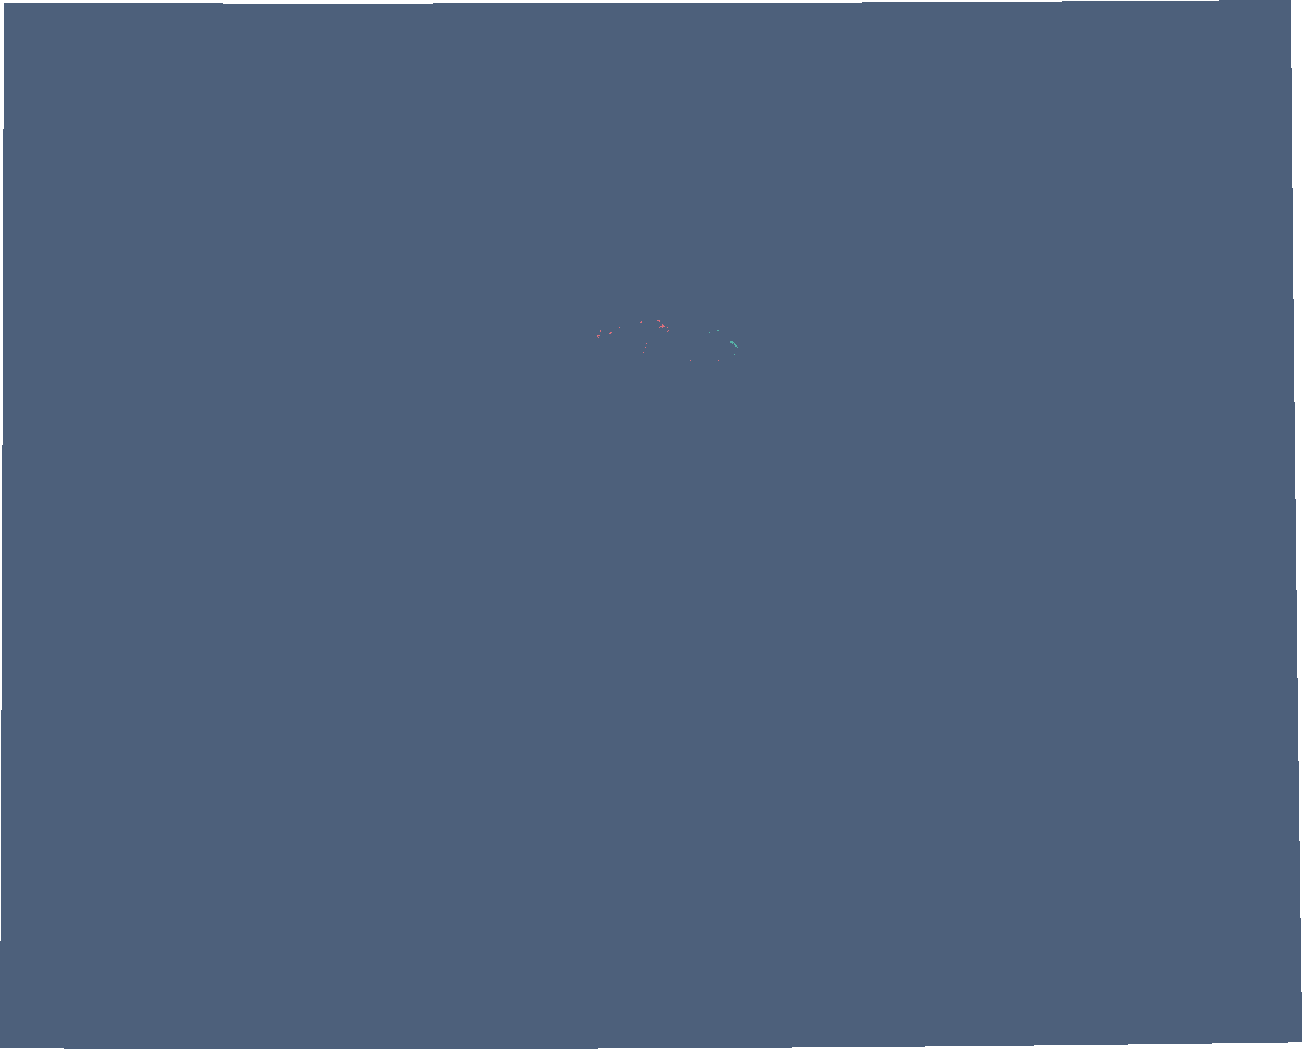
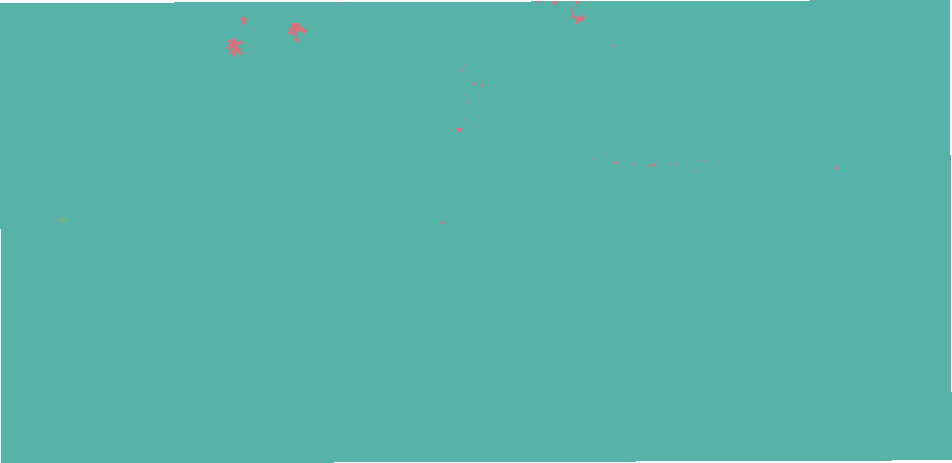
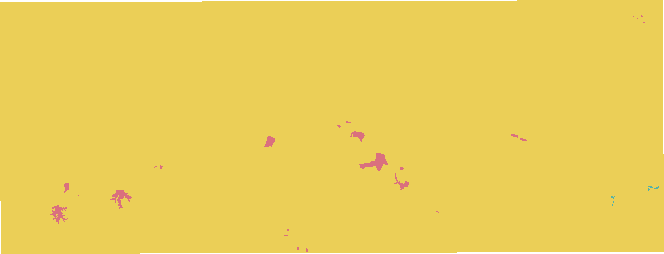

In [22]:
from rasterio.warp import calculate_default_transform, reproject, Resampling, transform_bounds
from rasterio.transform import array_bounds
from PIL import Image

OUT = "web/artifacts"
os.makedirs(OUT, exist_ok=True)
rgba = {KODE[k]: tuple(int(WARNA[k][i:i + 2], 16) for i in (1, 3, 5)) + (200,) for k in KELAS}
tiles = []
for nama, path in kelas_hasil.items():
    with rasterio.open(path) as s:
        arr = s.read(1)
        tr, w, h = calculate_default_transform(s.crs, "EPSG:4326", s.width, s.height, *s.bounds)
        dst = np.zeros((h, w), np.uint8)
        reproject(arr, dst, src_transform=s.transform, src_crs=s.crs, dst_transform=tr, dst_crs="EPSG:4326",
                  resampling=Resampling.nearest, src_nodata=0, dst_nodata=0)
        west, south, east, north = array_bounds(h, w, tr)
        img = np.zeros((h, w, 4), np.uint8)
        for c, col in rgba.items(): img[dst == c] = col
        Image.fromarray(img).save(f"{OUT}/{nama}_kelas.png", optimize=True)
        luas_piksel_ha = s.res[0] * s.res[1] / 1e4
        tiles.append(dict(name=nama, png=f"artifacts/{nama}_kelas.png", bounds=[[south, west], [north, east]], resolution_m=int(s.res[0]),
                          area_ha={NAMA[k]: round(float((arr == KODE[k]).sum() * luas_piksel_ha), 1) for k in KELAS}))

import folium
m = folium.Map(location=[-7.3, 112.5], zoom_start=9, tiles=None)
folium.TileLayer("https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}", attr="Google Satellite", name="Google Satellite", max_zoom=20).add_to(m)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(m)
for t in tiles:
    folium.raster_layers.ImageOverlay(f"{OUT}/{t['name']}_kelas.png", bounds=t["bounds"], opacity=0.8, name=t["name"]).add_to(m)
folium.GeoJson(sampel.assign(warna=sampel["label"].map(WARNA)).to_json(), name="Sampel", show=False,
               style_function=lambda f: dict(color=f["properties"]["warna"], weight=2, fillOpacity=0),
               tooltip=folium.GeoJsonTooltip(["label"])).add_to(m)
legend = "".join(f'<div><span style="background:{WARNA[k]};display:inline-block;width:12px;height:12px;margin-right:6px"></span>{NAMA[k]}</div>' for k in KELAS)
m.get_root().html.add_child(folium.Element(f'<div style="position:fixed;bottom:24px;left:24px;z-index:9999;background:white;padding:8px 12px;border:1px solid #888;border-radius:4px;font-size:13px">{legend}</div>'))
folium.LayerControl().add_to(m)
m


In [23]:
# simpan artefak untuk Streamlit dan web statis
rep = classification_report(y_test, y_pred, labels=KELAS, target_names=[NAMA[k] for k in KELAS], output_dict=True, zero_division=0)
counts = {NAMA[k]: dict(sampel_total=int(tabel_split.loc[k, "Total"]), sampel_train=int(tabel_split.loc[k, "Training"]), sampel_test=int(tabel_split.loc[k, "Testing"])) for k in KELAS}
json.dump(dict(classes={NAMA[k]: WARNA[k] for k in KELAS}, features=FITUR, counts=counts, models=hasil_model, best_model=best, test_size=TEST_SIZE,
               confusion=dict(labels=[NAMA[k] for k in KELAS], matrix=cm.tolist()), report=rep, importance=imp),
          open(f"{OUT}/metrics.json", "w"), indent=1)
json.dump(tiles, open(f"{OUT}/tiles.json", "w"), indent=1)
sampel.assign(kelas=sampel["label"].map(NAMA), warna=sampel["label"].map(WARNA))[["kelas", "warna", "geometry"]].to_file(f"{OUT}/samples.geojson", driver="GeoJSON")
print("Artefak tersimpan di", OUT, "| model terbaik:", best)

Artefak tersimpan di web/artifacts | model terbaik: LightGBM


## 15. Sistem Informasi: Streamlit dan Web Statis

Tiga sel berikut menulis file yang dibutuhkan langsung dari notebook ini: `web/content.json` (teks data understanding), `app.py` (Streamlit), dan `web/index.html` (web statis).

In [24]:
import json
CONTENT = json.loads(r'''{
 "judul": "Klasifikasi Penggunaan dan Penutup Lahan Jawa Timur dengan Sentinel-2A",
 "tujuan": [
  "Memetakan penutup/penggunaan lahan (land cover & land use) Jawa Timur ke dalam 6 kelas: sawah, bangunan, mangrove, lahan hijau, laut lepas, danau (ranu).",
  "Membedakan sawah dari lahan non-sawah yang terbangun/bervegetasi lain memakai band spektral dan indeks vegetasi, air, serta lahan terbangun.",
  "Membandingkan beberapa algoritma machine learning dan memilih model dengan akurasi dan F1 tertinggi pada data uji yang terpisah per poligon.",
  "Menyajikan hasil sebagai sistem informasi geografis berbasis web di atas citra satelit, sebagai dasar analisis spasial tata guna lahan dan kebijakan (alih fungsi lahan sawah, perlindungan mangrove, pengelolaan danau)."
 ],
 "koleksi": [
  "Citra: Sentinel-2 Level-2A melalui OpenEO Copernicus Data Space (koleksi SENTINEL2_L2A), komposit median pada periode yang diatur di notebook.",
  "Pra-proses: masking awan dan bayangan awan dengan band SCL (mask_scl_dilation), lalu median terhadap waktu. 10 band: B02-B07, B08, B8A, B11, B12; diproyeksikan ke EPSG:32749 (UTM 49S).",
  "Zona unduhan: sawah+bangunan dan lahan hijau (10 m), danau, mangrove, dan laut (20 m), mengikuti sebaran sampel.",
  "Sampel: 291 poligon hasil digitasi (shapefile) untuk 6 kelas; kelas Bangunan berasal dari sampel non-sawah. Satu sampel = rata-rata nilai band satu poligon."
 ],
 "acuan": {
  "sumber": "SNI 7645-1:2014 Klasifikasi penutup lahan (skala kecil dan menengah) dan klasifikasi penutup lahan KLHK (23 kelas). Periksa kode dan nama resmi pada dokumen aslinya sebelum dikutip di laporan.",
  "struktur": [
   [
    "Daerah bervegetasi - pertanian",
    "Sawah, pertanian lahan kering, perkebunan, tambak"
   ],
   [
    "Daerah bervegetasi - bukan pertanian",
    "Hutan lahan kering, hutan mangrove, hutan rawa, hutan tanaman, semak belukar, padang rumput"
   ],
   [
    "Daerah tak bervegetasi",
    "Permukiman dan lahan bukan pertanian yang berkaitan, tanah terbuka, pertambangan"
   ],
   [
    "Perairan",
    "Tubuh air (danau, waduk, sungai), rawa, laut"
   ]
  ],
  "pemetaan": [
   [
    "Sawah",
    "Pertanian - sawah"
   ],
   [
    "Bangunan",
    "Permukiman / lahan terbangun (kelas non-sawah)"
   ],
   [
    "Mangrove",
    "Hutan mangrove"
   ],
   [
    "Lahan hijau",
    "Vegetasi non-sawah: hutan lahan kering, kebun campur, semak"
   ],
   [
    "Laut lepas",
    "Perairan - laut"
   ],
   [
    "Danau",
    "Perairan darat - danau/ranu"
   ]
  ]
 },
 "band": [
  {
   "kode": "B1",
   "nama": "Coastal aerosol",
   "panjang_gelombang_nm": 442.7,
   "resolusi_m": 60,
   "kegunaan": "Koreksi aerosol atmosfer, studi pesisir"
  },
  {
   "kode": "B2",
   "nama": "Blue",
   "panjang_gelombang_nm": 492.4,
   "resolusi_m": 10,
   "kegunaan": "Penetrasi air, pembeda tanah/vegetasi, komponen EVI/BSI"
  },
  {
   "kode": "B3",
   "nama": "Green",
   "panjang_gelombang_nm": 559.8,
   "resolusi_m": 10,
   "kegunaan": "Puncak pantulan hijau vegetasi, komponen NDWI/MNDWI"
  },
  {
   "kode": "B4",
   "nama": "Red",
   "panjang_gelombang_nm": 664.6,
   "resolusi_m": 10,
   "kegunaan": "Serapan klorofil, komponen NDVI"
  },
  {
   "kode": "B5",
   "nama": "Vegetation Red Edge 1",
   "panjang_gelombang_nm": 704.1,
   "resolusi_m": 20,
   "kegunaan": "Kandungan klorofil, NDRE"
  },
  {
   "kode": "B6",
   "nama": "Vegetation Red Edge 2",
   "panjang_gelombang_nm": 740.5,
   "resolusi_m": 20,
   "kegunaan": "Struktur kanopi"
  },
  {
   "kode": "B7",
   "nama": "Vegetation Red Edge 3",
   "panjang_gelombang_nm": 782.8,
   "resolusi_m": 20,
   "kegunaan": "Struktur kanopi, transisi ke NIR"
  },
  {
   "kode": "B8",
   "nama": "NIR",
   "panjang_gelombang_nm": 832.8,
   "resolusi_m": 10,
   "kegunaan": "Biomassa vegetasi, batas darat-air"
  },
  {
   "kode": "B8A",
   "nama": "Narrow NIR",
   "panjang_gelombang_nm": 864.7,
   "resolusi_m": 20,
   "kegunaan": "Vegetasi (NIR sempit), NDRE"
  },
  {
   "kode": "B9",
   "nama": "Water vapour",
   "panjang_gelombang_nm": 945.1,
   "resolusi_m": 60,
   "kegunaan": "Uap air atmosfer (tidak dipakai)"
  },
  {
   "kode": "B10",
   "nama": "SWIR - Cirrus",
   "panjang_gelombang_nm": 1373.5,
   "resolusi_m": 60,
   "kegunaan": "Deteksi awan cirrus (tidak ada di Level-2A)"
  },
  {
   "kode": "B11",
   "nama": "SWIR 1",
   "panjang_gelombang_nm": 1613.7,
   "resolusi_m": 20,
   "kegunaan": "Kadar air vegetasi/tanah, lahan terbangun, MNDWI/NDBI"
  },
  {
   "kode": "B12",
   "nama": "SWIR 2",
   "panjang_gelombang_nm": 2202.4,
   "resolusi_m": 20,
   "kegunaan": "Tanah terbuka, lahan terbangun, BSI"
  }
 ],
 "indeks": [
  {
   "nama": "NDVI",
   "rumus": "(B8 - B4) / (B8 + B4)",
   "kegunaan": "Kehijauan vegetasi (-1..1)"
  },
  {
   "nama": "EVI",
   "rumus": "2.5 x (B8 - B4) / (B8 + 6xB4 - 7.5xB2 + 1)",
   "kegunaan": "Vegetasi, tidak mudah jenuh pada kanopi rapat"
  },
  {
   "nama": "SAVI",
   "rumus": "1.5 x (B8 - B4) / (B8 + B4 + 0.5)",
   "kegunaan": "Vegetasi dengan koreksi pengaruh tanah"
  },
  {
   "nama": "NDWI",
   "rumus": "(B3 - B8) / (B3 + B8)",
   "kegunaan": "Tubuh air terbuka (McFeeters)"
  },
  {
   "nama": "MNDWI",
   "rumus": "(B3 - B11) / (B3 + B11)",
   "kegunaan": "Air; menekan bangunan dibanding NDWI"
  },
  {
   "nama": "NDBI",
   "rumus": "(B11 - B8) / (B11 + B8)",
   "kegunaan": "Lahan terbangun"
  },
  {
   "nama": "NDMI",
   "rumus": "(B8 - B11) / (B8 + B11)",
   "kegunaan": "Kadar air vegetasi (sawah tergenang, mangrove)"
  },
  {
   "nama": "NDRE",
   "rumus": "(B8A - B5) / (B8A + B5)",
   "kegunaan": "Klorofil / kondisi tanaman"
  },
  {
   "nama": "BSI",
   "rumus": "((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2))",
   "kegunaan": "Tanah terbuka / lahan kering"
  },
  {
   "nama": "CMRI",
   "rumus": "NDVI - NDWI",
   "kegunaan": "Combined Mangrove Recognition Index"
  },
  {
   "nama": "MVI",
   "rumus": "(B8 - B3) / (B11 - B3)",
   "kegunaan": "Mangrove Vegetation Index (dipotong -50..50)"
  }
 ],
 "catatan": [
  "Nilai band dibagi 10000 menjadi reflektansi 0-1 sebelum indeks dihitung.",
  "Total fitur model: 10 band + 11 indeks = 21 fitur."
 ]
}''')
json.dump(CONTENT, open('web/content.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
print('web/content.json ditulis')

web/content.json ditulis


In [25]:
import os
os.makedirs("web", exist_ok=True)
with open("app.py", "w", encoding="utf-8") as f:
    f.write('"""Streamlit - Sistem Informasi LULC Jawa Timur. Jalankan: streamlit run app.py"""\nimport json, os\nimport pandas as pd, streamlit as st, folium\nfrom streamlit_folium import st_folium\n\nART = "web/artifacts"\nst.set_page_config(page_title="LULC Jawa Timur", layout="wide")\ncontent = json.load(open("web/content.json", encoding="utf-8"))\nhave = os.path.exists(f"{ART}/metrics.json")\nM = json.load(open(f"{ART}/metrics.json")) if have else None\nT = json.load(open(f"{ART}/tiles.json")) if have else []\n\nst.title(content["judul"])\ntab_map, tab_data, tab_band, tab_model, tab_proc = st.tabs(\n    ["Peta hasil", "Data understanding", "Band & fitur", "Model & akurasi", "Proses"])\n\nwith tab_map:\n    if not have:\n        st.warning("Artefak belum ada. Jalankan 02_pipeline.py lebih dulu.")\n    else:\n        c1, c2 = st.columns([3, 1])\n        with c2:\n            zones = st.multiselect("Zona hasil klasifikasi", [t["name"] for t in T], [t["name"] for t in T])\n            op = st.slider("Opasitas", 0.1, 1.0, 0.8)\n            show_s = st.checkbox("Tampilkan poligon sampel", False)\n            st.markdown("**Legenda**")\n            for k, v in M["classes"].items():\n                st.markdown(f"<span style=\'background:{v};padding:2px 10px;border-radius:3px\'>&nbsp;</span> {k}", unsafe_allow_html=True)\n            st.caption("Luas per kelas (ha)")\n            sel = [t for t in T if t["name"] in zones]\n            if sel: st.dataframe(pd.DataFrame({t["name"]: t["area_ha"] for t in sel}), use_container_width=True)\n        with c1:\n            m = folium.Map(location=[-7.3, 112.5], zoom_start=9, tiles=None)\n            folium.TileLayer("https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}", attr="Google Satellite",\n                             name="Google Satellite", max_zoom=20).add_to(m)\n            folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)\n            for t in sel:\n                folium.raster_layers.ImageOverlay(f"{ART}/{t[\'name\']}_kelas.png", bounds=t["bounds"],\n                                                  opacity=op, name=t["name"]).add_to(m)\n            if sel:\n                m.fit_bounds([[min(t["bounds"][0][0] for t in sel), min(t["bounds"][0][1] for t in sel)],\n                              [max(t["bounds"][1][0] for t in sel), max(t["bounds"][1][1] for t in sel)]])\n            if show_s:\n                folium.GeoJson(f"{ART}/samples.geojson", name="Sampel",\n                    style_function=lambda f: dict(color=f["properties"]["warna"], weight=2, fillOpacity=0),\n                    tooltip=folium.GeoJsonTooltip(["kelas"])).add_to(m)\n            folium.LayerControl().add_to(m)\n            st_folium(m, height=620, use_container_width=True, returned_objects=[])\n\nwith tab_data:\n    st.subheader("Tujuan analisis land use & land cover")\n    for x in content["tujuan"]: st.markdown(f"- {x}")\n    st.subheader("Pengumpulan data")\n    for x in content["koleksi"]: st.markdown(f"- {x}")\n    st.subheader("Acuan klasifikasi lahan Indonesia")\n    st.write(content["acuan"]["sumber"])\n    st.table(pd.DataFrame(content["acuan"]["struktur"], columns=["Kelompok", "Contoh kelas"]))\n    st.markdown("**Pemetaan ke 6 kelas penelitian**")\n    st.table(pd.DataFrame(content["acuan"]["pemetaan"], columns=["Kelas penelitian", "Padanan pada acuan"]))\n    if have:\n        st.subheader("Jumlah kelas dan data training/testing")\n        st.write(f"Jumlah kelas: **{len(M[\'classes\'])}**. Split stratifikasi {int((1-M[\'test_size\'])*100)}% training / {int(M[\'test_size\']*100)}% testing; "\n                 "satu sampel = rata-rata nilai band di dalam satu poligon.")\n        df = pd.DataFrame(M["counts"]).T; df.loc["Total"] = df.sum()\n        st.dataframe(df.astype(int), use_container_width=True)\n\nwith tab_band:\n    st.subheader("Band Sentinel-2A (MSI)")\n    st.dataframe(pd.DataFrame(content["band"]), use_container_width=True, hide_index=True)\n    st.subheader("Fitur turunan (indeks) dan rumusnya")\n    st.dataframe(pd.DataFrame(content["indeks"]), use_container_width=True, hide_index=True)\n    for x in content["catatan"]: st.caption(x)\n    if have:\n        st.subheader("Kepentingan fitur (permutation importance, model terbaik)")\n        st.bar_chart(pd.DataFrame(M["importance"], columns=["fitur", "penurunan akurasi"]).set_index("fitur"))\n\nwith tab_model:\n    if have:\n        df = pd.DataFrame(M["models"]).sort_values("test_accuracy", ascending=False)\n        st.success(f"Model terbaik: {M[\'best_model\']}")\n        st.dataframe(df, use_container_width=True, hide_index=True)\n        st.subheader("Confusion matrix (data uji)")\n        cm = pd.DataFrame(M["confusion"]["matrix"], index=M["confusion"]["labels"], columns=M["confusion"]["labels"])\n        st.dataframe(cm, use_container_width=True)\n        st.subheader("Precision / recall / F1 per kelas")\n        rep = pd.DataFrame(M["report"]).T\n        st.dataframe(rep, use_container_width=True)\n\nwith tab_proc:\n    st.markdown("""\n1. **Ambil citra**: komposit median Sentinel-2 L2A 10 band dari OpenEO Copernicus menjadi GeoTIFF per zona.\n2. **Ekstraksi**: rata-rata nilai band di dalam tiap poligon sampel.\n3. **Fitur**: 10 band ditambah 11 indeks (NDVI, EVI, SAVI, NDWI, MNDWI, NDBI, NDMI, NDRE, BSI, CMRI, MVI).\n4. **Split**: 80% training dan 20% testing, stratifikasi per kelas.\n5. **Model**: Random Forest, Extra Trees, HistGradientBoosting, SVM, k-NN, MLP, Logistic Regression, XGBoost, LightGBM; dibandingkan dengan CV 5-fold dan data uji.\n6. **Klasifikasi**: model dengan akurasi uji tertinggi dipakai memprediksi seluruh GeoTIFF.\n7. **Visualisasi**: hasil menjadi GeoTIFF kelas dan PNG overlay, ditampilkan di Leaflet/folium di atas Google Satellite.\n""")\n')
print("Wrote app.py successfully")

Wrote app.py successfully


In [26]:
import os
os.makedirs("web", exist_ok=True)
with open("web/index.html", "w", encoding="utf-8") as f:
    f.write('<!doctype html>\n<html lang="id"><head><meta charset="utf-8">\n<meta name="viewport" content="width=device-width, initial-scale=1">\n<title>LULC Jawa Timur - Sentinel-2A</title>\n<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">\n<style>\n:root{--ink:#14232b;--mut:#5b6b73;--bg:#f4f7f8;--card:#fff;--ln:#d5dee2;--ac:#0b6e7f}\n@media(prefers-color-scheme:dark){:root{--ink:#e6eef1;--mut:#9fb0b8;--bg:#10181c;--card:#172228;--ln:#2b3a41;--ac:#4fb6c7}}\n*{box-sizing:border-box}body{margin:0;font:16px/1.55 "Segoe UI",system-ui,sans-serif;background:var(--bg);color:var(--ink)}\nheader{padding:28px 5vw 12px}h1{margin:0 0 4px;font-size:1.6rem}header p{margin:0;color:var(--mut);max-width:70ch}\n#mapwrap{display:grid;grid-template-columns:1fr 280px;gap:16px;padding:12px 5vw}\n#map{height:68vh;min-height:420px;border:1px solid var(--ln);border-radius:6px}\naside{background:var(--card);border:1px solid var(--ln);border-radius:6px;padding:14px;font-size:.92rem;overflow:auto;max-height:68vh}\naside h3{margin:.2rem 0 .5rem;font-size:1rem}.sw{display:inline-block;width:14px;height:14px;border-radius:3px;margin-right:8px;vertical-align:-2px}\nmain{padding:0 5vw 48px;max-width:1200px}section{margin-top:36px}h2{font-size:1.25rem;border-bottom:2px solid var(--ac);padding-bottom:4px}\ntable{border-collapse:collapse;width:100%;background:var(--card);font-size:.9rem}th,td{border:1px solid var(--ln);padding:6px 9px;text-align:left}th{background:color-mix(in srgb,var(--ac) 14%,var(--card))}\n.scroll{overflow-x:auto}code{font-family:Consolas,monospace;font-size:.88em}li{margin:.25rem 0}.note{color:var(--mut);font-size:.9rem}\n.best{font-weight:600;background:color-mix(in srgb,var(--ac) 12%,var(--card))}\n@media(max-width:860px){#mapwrap{grid-template-columns:1fr}aside{max-height:none}}\n</style></head><body>\n<header><h1 id="judul"></h1><p>Web statis: proses, data, dan hasil klasifikasi. Dibuka lewat server lokal (<code>python -m http.server</code> di folder <code>web</code>).</p></header>\n<div id="mapwrap"><div id="map"></div>\n<aside><h3>Legenda</h3><div id="legend"></div><h3 style="margin-top:14px">Lapisan</h3><div id="layers"></div>\n<label>Opasitas <input id="op" type="range" min="0.1" max="1" step="0.05" value="0.8"></label><br>\n<label><input id="smp" type="checkbox"> Poligon sampel</label>\n<h3 style="margin-top:14px">Luas (ha)</h3><div id="area" class="note">Pilih zona pada peta.</div></aside></div>\n<main>\n<section><h2>Tujuan analisis</h2><ul id="tujuan"></ul></section>\n<section><h2>Pengumpulan data</h2><ul id="koleksi"></ul></section>\n<section><h2>Acuan klasifikasi lahan di Indonesia</h2><p id="acuan" class="note"></p>\n<div class="scroll"><table id="struktur"></table></div><p></p><div class="scroll"><table id="pemetaan"></table></div></section>\n<section><h2>Jumlah kelas, data training, dan testing</h2><p id="split" class="note"></p><div class="scroll"><table id="counts"></table></div></section>\n<section><h2>Band Sentinel-2A</h2><div class="scroll"><table id="band"></table></div></section>\n<section><h2>Fitur turunan dan rumus</h2><div class="scroll"><table id="indeks"></table></div><p id="catatan" class="note"></p></section>\n<section><h2>Perbandingan model</h2><div class="scroll"><table id="models"></table></div><p id="bestnote"></p></section>\n<section><h2>Confusion matrix (data uji)</h2><div class="scroll"><table id="cm"></table></div></section>\n<section><h2>Kepentingan fitur</h2><div class="scroll"><table id="imp"></table></div></section>\n<section><h2>Proses</h2><ol>\n<li>Ambil komposit median Sentinel-2 L2A 10 band dari OpenEO Copernicus (GeoTIFF per zona).</li><li>Hitung rata-rata band di dalam tiap poligon sampel.</li>\n<li>Hitung 10 band + 11 indeks (21 fitur).</li><li>Bagi data 80% training dan 20% testing (stratifikasi).</li>\n<li>Latih dan bandingkan 9 algoritma dengan CV 5-fold dan data uji.</li><li>Pakai model terbaik untuk mengklasifikasi seluruh GeoTIFF.</li>\n<li>Tampilkan di Leaflet di atas Google Satellite.</li></ol></section>\n</main>\n<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>\n<script>\nconst $=id=>document.getElementById(id);\nconst tbl=(el,head,rows,cls)=>{$(el).innerHTML="<thead><tr>"+head.map(h=>`<th>${h}</th>`).join("")+"</tr></thead><tbody>"+rows.map((r,i)=>`<tr class="${cls&&cls(i)||""}">`+r.map(c=>`<td>${c}</td>`).join("")+"</tr>").join("")+"</tbody>";};\nconst ul=(el,a)=>$(el).innerHTML=a.map(x=>`<li>${x}</li>`).join("");\nconst get=u=>fetch(u).then(r=>{if(!r.ok)throw 0;return r.json()}).catch(()=>null);\nconst map=L.map("map").setView([-7.3,112.5],9);\nL.tileLayer("https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}",{maxZoom:20,attribution:"Google Satellite"}).addTo(map);\nconst f2=x=>(+x).toFixed(3);\n(async()=>{\n const C=await get("content.json"); if(!C){document.body.insertAdjacentHTML("afterbegin","<p style=\'padding:20px\'>content.json tidak ditemukan. Buka lewat server lokal.</p>");return}\n $("judul").textContent=C.judul; ul("tujuan",C.tujuan); ul("koleksi",C.koleksi); $("acuan").textContent=C.acuan.sumber;\n tbl("struktur",["Kelompok","Contoh kelas"],C.acuan.struktur); tbl("pemetaan",["Kelas penelitian","Padanan pada acuan"],C.acuan.pemetaan);\n tbl("band",["Band","Nama","Panjang gelombang (nm)","Resolusi (m)","Kegunaan"],C.band.map(b=>[b.kode,b.nama,b.panjang_gelombang_nm,b.resolusi_m,b.kegunaan]));\n tbl("indeks",["Indeks","Rumus","Kegunaan"],C.indeks.map(i=>[i.nama,`<code>${i.rumus}</code>`,i.kegunaan])); $("catatan").textContent=C.catatan.join(" ");\n const M=await get("artifacts/metrics.json"),T=await get("artifacts/tiles.json");\n if(!M){$("split").textContent="Hasil belum ada. Jalankan 02_pipeline.py.";return}\n $("legend").innerHTML=Object.entries(M.classes).map(([k,v])=>`<div><span class="sw" style="background:${v}"></span>${k}</div>`).join("");\n const k=Object.keys(M.counts); $("split").textContent=`${k.length} kelas. Split stratifikasi ${(1-M.test_size)*100}% training / ${M.test_size*100}% testing. Satu sampel = rata-rata band satu poligon.`;\n const keys=["sampel_total","sampel_train","sampel_test"];\n const rows=k.map(c=>[c,...keys.map(x=>M.counts[c][x])]); rows.push(["Total",...keys.map((x,i)=>rows.reduce((s,r)=>s+r[i+1],0))]);\n tbl("counts",["Kelas","Total sampel","Training","Testing"],rows);\n const ms=[...M.models].sort((a,b)=>b.test_accuracy-a.test_accuracy);\n tbl("models",["Model","CV F1 (rerata)","CV F1 (sd)","Akurasi uji","F1-macro uji","Kappa uji","Waktu (s)"],ms.map(m=>[m.model,f2(m.cv_f1_mean),f2(m.cv_f1_std),f2(m.test_accuracy),f2(m.test_f1_macro),f2(m.test_kappa),m.seconds]),i=>ms[i].model===M.best_model?"best":"");\n $("bestnote").innerHTML=`Model terbaik: <b>${M.best_model}</b>`;\n tbl("cm",["Aktual \\\\ Prediksi",...M.confusion.labels],M.confusion.matrix.map((r,i)=>[M.confusion.labels[i],...r]));\n tbl("imp",["Fitur","Penurunan F1 saat diacak"],M.importance.map(x=>[x[0],f2(x[1])]));\n const layers={},ov=()=>+$("op").value;\n T.forEach((t,i)=>{layers[t.name]=L.imageOverlay(t.png,t.bounds,{opacity:ov()}); layers[t.name].addTo(map);\n  $("layers").insertAdjacentHTML("beforeend",`<label><input type="checkbox" checked data-n="${t.name}"> ${t.name} (${t.resolution_m} m)</label><br>`);});\n const showArea=()=>{const on=[...document.querySelectorAll("#layers input:checked")].map(x=>x.dataset.n);\n  $("area").innerHTML=T.filter(t=>on.includes(t.name)).map(t=>`<b>${t.name}</b><br>`+Object.entries(t.area_ha).map(([a,b])=>`${a}: ${b.toLocaleString("id-ID")}`).join("<br>")).join("<hr>")||"Pilih zona.";};\n $("layers").onchange=e=>{const l=layers[e.target.dataset.n];e.target.checked?l.addTo(map):map.removeLayer(l);showArea()};\n $("op").oninput=()=>Object.values(layers).forEach(l=>l.setOpacity(ov())); showArea();\n const s=await get("artifacts/samples.geojson"); let sl=null;\n if(s)$("smp").onchange=e=>{if(e.target.checked){sl=L.geoJSON(s,{style:f=>({color:f.properties.warna,weight:2,fill:false})}).bindTooltip(l=>l.feature.properties.kelas).addTo(map)}else if(sl)map.removeLayer(sl)};\n if(T.length)map.fitBounds(L.featureGroup(Object.values(layers)).getBounds());\n})();\n</script></body></html>')
print("Wrote web/index.html successfully")

Wrote web/index.html successfully


## 16. Menjalankan

Buka terminal di folder notebook ini:

```bash
streamlit run app.py
```

Web statis: `cd web`, jalankan `python -m http.server 8000`, lalu buka http://localhost:8000.

Deploy Streamlit Community Cloud: unggah `app.py`, folder `web/` (berisi `content.json` dan `artifacts/`), dan `requirements.txt` berisi `streamlit`, `folium`, `streamlit-folium`, `pandas`.